# Fuga de datos: lo que el modelo no debería haber visto

En `02-carga/01_division_y_dataloader` separamos las flores en entrenamiento, validación y prueba. Separar es la mitad del trabajo. La otra mitad es que nada de la prueba se cuele en las decisiones que se toman al construir el modelo. Cuando se cuela, la exactitud medida sale mejor que la que el modelo va a tener con datos nuevos, y nada avisa: no hay un error, solo un número demasiado bueno. Eso se llama **fuga de datos** (*data leakage*).

El curso recomienda dos lecturas sobre el tema: dos capítulos de la guía de scikit-learn (*Common pitfalls and recommended practices* y *Cross-validation*) y el artículo *Data Leakage in Machine Learning* de Jason Brownlee, en Machine Learning Mastery. Este notebook lleva sus ideas a código, y cada fuga se mide junto a su versión correcta:

- elegir características mirando todos los datos (el ejemplo de scikit-learn, repetido 50 veces);
- normalizar con todos los datos, y por qué con las flores casi no importa;
- datos que cambian con el tiempo: mezclar al dividir y normalizar la prueba con sus propias estadísticas;
- aumentar los datos antes de dividir;
- copias de la misma foto a ambos lados de la división oficial de Oxford Flowers 102, que buscamos y revisamos una por una;
- elegir el modelo mirando la prueba;
- validación cruzada hecha a mano, simple y estratificada, con la preparación dentro de cada pliegue;
- grupos de datos que dependen entre sí.

Para que todo sea rápido, trabajamos con miniaturas de 32 × 32 de las fotos y con clasificadores que no necesitan entrenamiento, como el vecino más cercano. Las cuentas toman segundos y las fugas se notan igual que con una red. scikit-learn no está entre los requisitos del curso, así que todo está escrito con PyTorch y NumPy; en cada caso decimos qué función de scikit-learn hace lo mismo.

El notebook tarda unos tres o cuatro minutos en una CPU.

**Contenido**

1. Preparación
2. Qué es la fuga de datos
3. Elegir características con todos los datos
4. Normalizar con todos los datos
5. Datos que cambian con el tiempo
6. Aumentar antes de dividir
7. Copias a ambos lados de la división oficial
8. Elegir con la prueba
9. Validación cruzada a mano
10. Grupos que dependen entre sí
11. Una lista de verificación
12. Resumen y ejercicios

## 1. Preparación

Las fotos, las etiquetas y la división oficial de Oxford Flowers 102 están en `modulo-3/data/flowers-102`, como en el resto del módulo (`00-acceso/01_un_dataset_propio`). Las etiquetas del archivo `.mat` van de 1 a 102, y les restamos 1. La división oficial está en `setid.mat`.

In [1]:
import hashlib
import time

import numpy as np
import scipy.io
import scipy.stats
import torch
from PIL import Image
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"                                    # modulo-3/data
datasets.Flowers102(root=RAIZ, download=True)       # descarga las fotos la primera vez
CARPETA = f"{RAIZ}/flowers-102"

etiquetas = torch.from_numpy(scipy.io.loadmat(f"{CARPETA}/imagelabels.mat")["labels"][0].astype(np.int64) - 1)
N = len(etiquetas)

division = scipy.io.loadmat(f"{CARPETA}/setid.mat")
oficial = {nombre: torch.from_numpy(division[clave][0].astype(np.int64) - 1)     # índices desde 0
           for nombre, clave in [("entrenamiento", "trnid"), ("validación", "valid"), ("prueba", "tstid")]}
print("fotos:", N, "  clases:", len(torch.unique(etiquetas)))
for nombre, indices in oficial.items():
    print(f"división oficial, {nombre:13s}: {len(indices):5d} fotos")

Versión de PyTorch: 2.11.0+cpu
fotos: 8189   clases: 102
división oficial, entrenamiento:  1020 fotos
división oficial, validación   :  1020 fotos
división oficial, prueba       :  6149 fotos


**Miniaturas.** Decodificar las 8.189 fotos completas cada vez que hace falta sería lento. Las reducimos una sola vez a 32 × 32 y trabajamos con eso. Dos detalles:

- `foto.draft("RGB", tamaño)` le pide al decodificador de JPEG una versión de la foto lo más parecida posible al tamaño pedido ([doc de Pillow, `Image.draft`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.draft)). El JPEG se decodifica ya reducido, que es mucho más rápido que decodificarlo entero y achicarlo después.
- Recortamos el cuadrado central antes de achicar, para no deformar la foto (`01-calidad/01_transforms_para_fotos`).

miniaturas: (8189, 3, 32, 32), torch.uint8, 25 MB, en 35 s


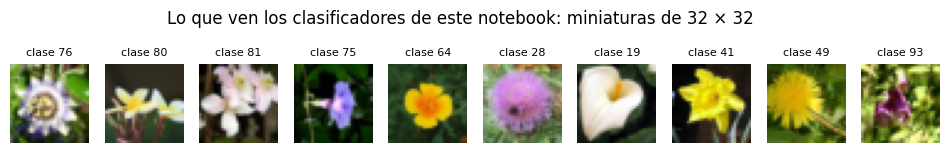

In [2]:
def miniatura(numero, lado=32):
    """La foto image_<numero>.jpg reducida a lado × lado, como tensor uint8 [3, lado, lado]."""
    with Image.open(f"{CARPETA}/jpg/image_{numero:05d}.jpg") as foto:
        foto.draft("RGB", (2 * lado, 2 * lado))
        foto = foto.convert("RGB")
        ancho, alto = foto.size
        corte = min(ancho, alto)
        izquierda, arriba = (ancho - corte) // 2, (alto - corte) // 2
        foto = foto.crop((izquierda, arriba, izquierda + corte, arriba + corte))
        foto = foto.resize((lado, lado), Image.Resampling.BILINEAR)
        return torch.from_numpy(np.array(foto)).permute(2, 0, 1)


inicio = time.perf_counter()
miniaturas = torch.stack([miniatura(i + 1) for i in range(N)])     # la foto i está en el archivo i + 1
print(f"miniaturas: {tuple(miniaturas.shape)}, {miniaturas.dtype}, "
      f"{miniaturas.numel() / 1e6:.0f} MB, en {time.perf_counter() - inicio:.0f} s")

X_flores = miniaturas.reshape(N, -1).float() / 255                # un vector de 3.072 números por foto

fig, ejes = plt.subplots(1, 10, figsize=(12, 1.6))
for eje, i in zip(ejes, range(0, N, N // 10)):
    eje.imshow(miniaturas[i].permute(1, 2, 0))
    eje.set_title(f"clase {etiquetas[i].item()}", fontsize=8)
    eje.axis("off")
plt.suptitle("Lo que ven los clasificadores de este notebook: miniaturas de 32 × 32", y=1.08)
plt.show()

**El clasificador.** El vecino más cercano no tiene parámetros que entrenar: para cada foto de prueba busca la foto de entrenamiento más parecida (la de menor distancia entre sus 3.072 números) y copia su etiqueta. Es un mal clasificador de flores, pero sirve muy bien para este notebook: es rápido, no tiene semillas ni hiperparámetros que oculten nada, y premia de inmediato cualquier copia de la prueba que haya quedado en el entrenamiento. En scikit-learn es `KNeighborsClassifier(n_neighbors=1)`.

In [3]:
def vecino_mas_cercano(X_entrenamiento, y_entrenamiento, X_prueba, lote=1000):
    """Etiqueta de la fila de X_entrenamiento más cercana a cada fila de X_prueba."""
    predicciones = []
    for inicio in range(0, len(X_prueba), lote):
        distancias = torch.cdist(X_prueba[inicio:inicio + lote], X_entrenamiento)
        predicciones.append(y_entrenamiento[distancias.argmin(dim=1)])
    return torch.cat(predicciones)


def exactitud(prediccion, verdad):
    return (prediccion == verdad).float().mean().item()


referencia = torch.cat([oficial["entrenamiento"], oficial["validación"]])
prediccion = vecino_mas_cercano(X_flores[referencia], etiquetas[referencia], X_flores[oficial["prueba"]])
print(f"vecino más cercano en la división oficial: {exactitud(prediccion, etiquetas[oficial['prueba']]):.2%}")
print(f"adivinar al azar entre 102 clases       : {1 / 102:.2%}")

vecino más cercano en la división oficial: 15.01%
adivinar al azar entre 102 clases       : 0.98%


15% con píxeles crudos, contra 1% al azar. Esa es la línea base. Lo que importa en este notebook no es el número en sí, sino cuánto sube cuando algo de la prueba se filtra.

## 2. Qué es la fuga de datos

Las dos lecturas la definen casi igual:

- scikit-learn: la fuga ocurre cuando, al construir el modelo, se usa información que no estaría disponible al momento de predecir. El resultado son estimaciones de rendimiento demasiado optimistas y, después, un rendimiento peor con datos realmente nuevos, por ejemplo en producción ([*Common pitfalls*, sección 12.2](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)).
- Brownlee: la fuga ocurre cuando se usa información de fuera del conjunto de entrenamiento para crear el modelo, y puede llevar a modelos demasiado optimistas, si no del todo inválidos ([*What is Data Leakage in Machine Learning?*](https://machinelearningmastery.com/data-leakage-machine-learning/)).

La idea de fondo es la del proyecto de punta a punta del módulo 1 (`05-profundizacion/06_proyecto_de_punta_a_punta`, sección 5): la prueba hace el papel de los datos que van a llegar después. Esos datos no se conocen al construir el modelo. Cualquier decisión que se tome mirando la prueba (qué características usar, con qué números normalizar, qué modelo elegir) hace que la prueba deje de representarlos. scikit-learn lo resume en una regla: los datos de prueba nunca se usan para decidir nada sobre el modelo, y nunca se llama a `fit` con ellos ([sección 12.2](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)).

¿Cómo se nota? Brownlee da una pista: un rendimiento que parece demasiado bueno para ser verdad. También advierte que la fuga es más común en datos complejos, entre ellos las imágenes y sonidos guardados en archivos separados ([*Do I have Data Leakage?*](https://machinelearningmastery.com/data-leakage-machine-learning/)), que es justo el caso de las flores.

## 3. Elegir características con todos los datos

El ejemplo central de scikit-learn ([sección 12.2.2](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage-during-pre-processing)) usa datos que no tienen nada que aprender: 200 ejemplos con 10.000 características al azar y una etiqueta binaria también al azar. Como la etiqueta no depende de nada, ningún modelo honesto puede pasar de 50% de exactitud. El ejemplo elige las 25 características "más relacionadas" con la etiqueta y entrena un clasificador con ellas:

- **mal**: elegir las 25 con los 200 ejemplos y después separar entrenamiento y prueba. scikit-learn obtiene 76% de exactitud;
- **bien**: separar primero y elegir las 25 solo con el entrenamiento. Obtiene 50%.

Para elegir, scikit-learn usa `SelectKBest`, que por defecto puntúa cada característica con el estadístico F del análisis de varianza (ANOVA), `f_classif` ([doc de `SelectKBest`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html)). El F compara cuánto se separan las medias de las clases con cuánto varían los datos dentro de cada clase: si las medias están lejos en comparación con la dispersión, la característica parece útil. Lo escribimos a mano y lo comprobamos contra `scipy.stats.f_oneway`, que calcula el mismo estadístico:

In [4]:
def puntaje_anova(X, y):
    """Estadístico F del ANOVA de cada columna de X según las clases de y (lo que calcula f_classif)."""
    clases = torch.unique(y)
    n, k = len(y), len(clases)
    media = X.mean(dim=0)
    entre = sum((y == c).sum() * (X[y == c].mean(dim=0) - media) ** 2 for c in clases) / (k - 1)
    dentro = sum(((X[y == c] - X[y == c].mean(dim=0)) ** 2).sum(dim=0) for c in clases) / (n - k)
    return entre / dentro


g = torch.Generator().manual_seed(0)
X_prueba_f = torch.randn(200, 50, generator=g, dtype=torch.float64)
y_prueba_f = torch.randint(0, 3, (200,), generator=g)
f_scipy = scipy.stats.f_oneway(*[X_prueba_f[y_prueba_f == c].numpy() for c in range(3)], axis=0).statistic
print("¿Igual que scipy?", np.allclose(puntaje_anova(X_prueba_f, y_prueba_f).numpy(), f_scipy))

¿Igual que scipy? True


En lugar del clasificador de *gradient boosting* del ejemplo usamos uno más simple, el **centroide más cercano**: calcula el promedio de cada clase en el entrenamiento y asigna cada ejemplo de prueba a la clase cuyo promedio está más cerca (en scikit-learn, `NearestCentroid`). La división es la misma del ejemplo: 150 ejemplos para entrenar y 50 para probar.

In [5]:
def centroide_mas_cercano(X_entrenamiento, y_entrenamiento, X_prueba):
    clases = torch.unique(y_entrenamiento)
    centroides = torch.stack([X_entrenamiento[y_entrenamiento == c].mean(dim=0) for c in clases])
    return clases[torch.cdist(X_prueba, centroides).argmin(dim=1)]


def seleccion_de_caracteristicas(semilla, k=25):
    g = torch.Generator().manual_seed(semilla)
    X = torch.randn(200, 10_000, generator=g)
    y = torch.randint(0, 2, (200,), generator=g)            # etiquetas al azar: no hay nada que aprender
    orden = torch.randperm(200, generator=g)
    ent, pru = orden[:150], orden[150:]

    resultado = {}
    for nombre, filas in [("mal", torch.arange(200)), ("bien", ent)]:
        elegidas = puntaje_anova(X[filas], y[filas]).topk(k).indices       # las k con mayor F
        pred = centroide_mas_cercano(X[ent][:, elegidas], y[ent], X[pru][:, elegidas])
        resultado[nombre] = exactitud(pred, y[pru])
        resultado[f"F en la prueba, {nombre}"] = puntaje_anova(X[pru][:, elegidas], y[pru]).mean().item()
    return resultado


r = seleccion_de_caracteristicas(semilla=0)
print(f"mal  (elegir con los 200, después separar): {r['mal']:.0%}")
print(f"bien (separar, después elegir con 150)    : {r['bien']:.0%}")

mal  (elegir con los 200, después separar): 90%
bien (separar, después elegir con 150)    : 44%


Lo mismo que en la lectura: muy por encima del azar con la fuga, alrededor del azar sin ella. Un solo resultado con 50 ejemplos de prueba es ruidoso, así que repetimos todo con 50 semillas distintas:

mal : 86.5% ± 4.4%   (mínimo 78%, máximo 100%)
bien: 49.0% ± 7.1%   (mínimo 40%, máximo 68%)


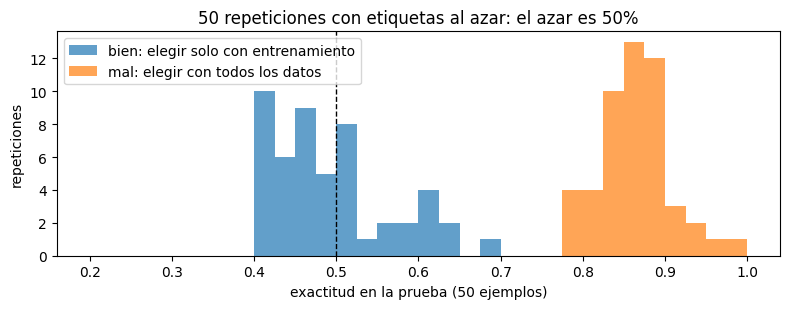

In [6]:
repeticiones = [seleccion_de_caracteristicas(semilla) for semilla in range(50)]
mal = np.array([r["mal"] for r in repeticiones])
bien = np.array([r["bien"] for r in repeticiones])
print(f"mal : {mal.mean():.1%} ± {mal.std():.1%}   (mínimo {mal.min():.0%}, máximo {mal.max():.0%})")
print(f"bien: {bien.mean():.1%} ± {bien.std():.1%}   (mínimo {bien.min():.0%}, máximo {bien.max():.0%})")

fig, eje = plt.subplots(figsize=(8, 3.2))
bordes = np.linspace(0.2, 1.0, 33)
eje.hist(bien, bins=bordes, alpha=0.7, label="bien: elegir solo con entrenamiento")
eje.hist(mal, bins=bordes, alpha=0.7, label="mal: elegir con todos los datos")
eje.axvline(0.5, color="black", linestyle="--", linewidth=1)
eje.set_xlabel("exactitud en la prueba (50 ejemplos)")
eje.set_ylabel("repeticiones")
eje.set_title("50 repeticiones con etiquetas al azar: el azar es 50%")
eje.legend()
plt.tight_layout()
plt.show()

Las dos distribuciones no se tocan: la peor repetición con fuga supera a la mejor sin fuga. Y lo único distinto entre las dos versiones es una línea, qué filas se usan para calcular el F.

¿Por qué funciona la trampa? Con 10.000 características al azar, algunas quedan correlacionadas con la etiqueta por pura casualidad en estos 200 ejemplos. Si se eligen mirando los 200, se eligen las que por casualidad separan bien **también los 50 de prueba**. El F de las características elegidas, medido solo en los ejemplos de prueba, lo muestra:

In [7]:
f_mal = np.mean([r["F en la prueba, mal"] for r in repeticiones])
f_bien = np.mean([r["F en la prueba, bien"] for r in repeticiones])
print(f"F promedio de las 25 elegidas, medido en los 50 ejemplos de prueba:")
print(f"   elegidas con todos los datos  : {f_mal:.2f}")
print(f"   elegidas solo con entrenamiento: {f_bien:.2f}")
print("   (sin relación con la etiqueta, el F promedio esperado es cercano a 1)")

F promedio de las 25 elegidas, medido en los 50 ejemplos de prueba:
   elegidas con todos los datos  : 3.68
   elegidas solo con entrenamiento: 1.13
   (sin relación con la etiqueta, el F promedio esperado es cercano a 1)


Las características elegidas con todos los datos separan las clases de la prueba varias veces más de lo que lo haría el azar. Las elegidas solo con el entrenamiento, no: su "relación" con la etiqueta era casualidad del entrenamiento y no se repite en datos nuevos.

scikit-learn insiste en que esto no es propio de la selección de características: el riesgo existe con casi cualquier transformación que se ajuste a los datos, como `StandardScaler`, `SimpleImputer` o `PCA` ([nota de la sección 12.2.2](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage-during-pre-processing)). La siguiente sección mide la más común, normalizar.

## 4. Normalizar con todos los datos

scikit-learn pone el ejemplo: si un paso de normalización divide por el promedio, ese promedio tiene que ser el del entrenamiento, no el de todos los datos; si la prueba entra en el cálculo, su información está influyendo en el modelo ([sección 12.2](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)). Brownlee lo llama "el pecado" de la fuga: normalizar o estandarizar todo el conjunto antes de evaluar ([*Perform Data Preparation Within Cross Validation Folds*](https://machinelearningmastery.com/data-leakage-machine-learning/)). En el módulo 1 seguimos esa regla al normalizar (`05-profundizacion/06_proyecto_de_punta_a_punta`, sección 7). ¿Cuánto cambia con las flores?

Hacemos una división al azar 70/15/15, como la de `02-carga/01_division_y_dataloader`, y calculamos la media y la desviación de cada canal con todas las fotos y solo con las de entrenamiento:

In [8]:
g = torch.Generator().manual_seed(0)
orden = torch.randperm(N, generator=g)
n_ent, n_val = int(0.70 * N), int(0.15 * N)
ent, val, pru = orden[:n_ent], orden[n_ent:n_ent + n_val], orden[n_ent + n_val:]
print(f"entrenamiento {len(ent)}, validación {len(val)}, prueba {len(pru)}")


def estadisticas_por_canal(indices):
    pixeles = miniaturas[indices].float().div(255).permute(1, 0, 2, 3).reshape(3, -1)
    return pixeles.mean(dim=1), pixeles.std(dim=1)


media_todo, desv_todo = estadisticas_por_canal(torch.arange(N))
media_ent, desv_ent = estadisticas_por_canal(ent)
print("media, todas las fotos     :", media_todo.numpy().round(4))
print("media, solo entrenamiento  :", media_ent.numpy().round(4))
print("desviación, todas las fotos:", desv_todo.numpy().round(4))
print("desviación, entrenamiento  :", desv_ent.numpy().round(4))
print(f"diferencia más grande: {max((media_todo - media_ent).abs().max(), (desv_todo - desv_ent).abs().max()):.4f}")

entrenamiento 5732, validación 1228, prueba 1229


media, todas las fotos     : [0.4756 0.3942 0.3078]
media, solo entrenamiento  : [0.4751 0.394  0.3081]
desviación, todas las fotos: [0.2799 0.2269 0.2593]
desviación, entrenamiento  : [0.2802 0.2266 0.2594]
diferencia más grande: 0.0004


Las estadísticas difieren en menos de 0.0005. Es lo esperable: 5.732 fotos sacadas al azar de las mismas 8.189 ya estiman muy bien la media y la desviación de todas. Probemos algo más exigente: normalizar cada uno de los 3.072 números de la miniatura por separado (3.072 medias y 3.072 desviaciones, más fáciles de mover que 3), y medir la exactitud del vecino más cercano en la prueba con cada versión:

In [9]:
for nombre, filas in [("todas las fotos", torch.arange(N)), ("solo entrenamiento", ent)]:
    media, desviacion = X_flores[filas].mean(dim=0), X_flores[filas].std(dim=0)
    Z = (X_flores - media) / desviacion
    pred = vecino_mas_cercano(Z[ent], etiquetas[ent], Z[pru])
    print(f"estadísticas de {nombre:18s}: exactitud en la prueba {exactitud(pred, etiquetas[pru]):.2%}")

estadísticas de todas las fotos   : exactitud en la prueba 18.39%


estadísticas de solo entrenamiento: exactitud en la prueba 18.39%


Las dos versiones dan exactamente la misma exactitud. Con las flores, normalizar con todo el conjunto es una fuga en principio y casi nada en la práctica. ¿Entonces da igual? No, por dos razones:

- seguir la regla no cuesta nada: se calculan las estadísticas con el entrenamiento y se guardan, como en el módulo 1;
- el efecto es chico **porque** el entrenamiento y la prueba vienen de la misma distribución. Cuando los datos cambian con el tiempo, deja de ser chico.

## 5. Datos que cambian con el tiempo

Inventamos un caso del mismo jardín. En el invernadero, un sensor mide dos cosas de cada planta para distinguir dos especies. La medición `a` es estable. La `b` viene de un sensor que se va descalibrando: su lectura sube 0.25 por mes. Juntamos 2.400 mediciones a lo largo de 12 meses:

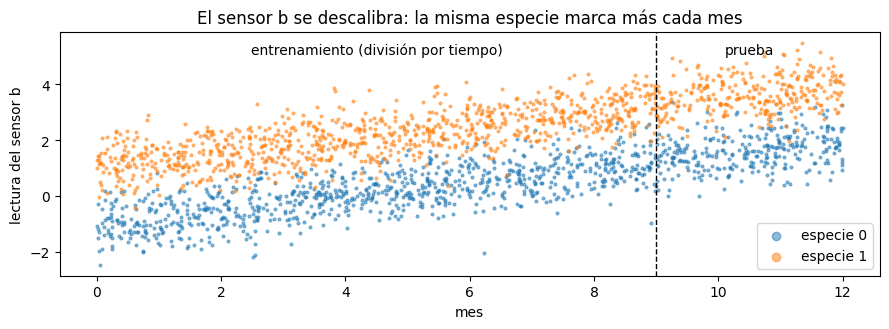

In [10]:
def medir_invernadero(n, mes_inicial, mes_final, g):
    mes = mes_inicial + torch.rand(n, generator=g) * (mes_final - mes_inicial)
    especie = torch.randint(0, 2, (n,), generator=g)
    signo = 2 * especie - 1.0
    a = 0.8 * signo + torch.randn(n, generator=g)                       # sensor estable
    b = 1.0 * signo + 0.6 * torch.randn(n, generator=g) + 0.25 * mes     # sensor que se descalibra
    return torch.stack([a, b], dim=1), especie, mes


def k_vecinos_binario(X_entrenamiento, y_entrenamiento, X_prueba, k=5):
    vecinos = torch.cdist(X_prueba, X_entrenamiento).topk(k, largest=False).indices
    return (y_entrenamiento[vecinos].float().mean(dim=1) > 0.5).long()     # votación de los k vecinos


def clasificar(X_ent, y_ent, X_pru, estadisticas_de=None, estadisticas_de_la_prueba=None):
    """Estandariza con las estadísticas de `estadisticas_de` (por defecto, el entrenamiento) y vota con 5 vecinos."""
    referencia = X_ent if estadisticas_de is None else estadisticas_de
    media, desviacion = referencia.mean(dim=0), referencia.std(dim=0)
    media_pru, desv_pru = (media, desviacion) if estadisticas_de_la_prueba is None else estadisticas_de_la_prueba
    return k_vecinos_binario((X_ent - media) / desviacion, y_ent, (X_pru - media_pru) / desv_pru)


g = torch.Generator().manual_seed(0)
X_inv, y_inv, mes_inv = medir_invernadero(2400, 0, 12, g)
X_prod, y_prod, mes_prod = medir_invernadero(600, 12, 15, g)       # lo que llega después, en uso

fig, eje = plt.subplots(figsize=(9, 3.4))
for especie, color in [(0, "tab:blue"), (1, "tab:orange")]:
    m = y_inv == especie
    eje.scatter(mes_inv[m], X_inv[m, 1], s=4, alpha=0.5, color=color, label=f"especie {especie}")
eje.axvline(9, color="black", linestyle="--", linewidth=1)
eje.text(4.5, X_inv[:, 1].max(), "entrenamiento (división por tiempo)", ha="center", va="top")
eje.text(10.5, X_inv[:, 1].max(), "prueba", ha="center", va="top")
eje.set_xlabel("mes")
eje.set_ylabel("lectura del sensor b")
eje.set_title("El sensor b se descalibra: la misma especie marca más cada mes")
eje.legend(loc="lower right", markerscale=3)
plt.tight_layout()
plt.show()

Las dos especies se separan bien dentro de un mismo mes, pero la nube completa sube con el tiempo: una planta de la especie 0 medida en el mes 11 marca lo mismo que una de la especie 1 medida en el mes 3. Comparamos dos formas de dividir las 2.400 mediciones en 1.800 para entrenar y 600 para probar, y miramos además qué pasa con lo que llega después, en los meses 12 a 15:

- **al azar**, mezclando todos los meses;
- **por tiempo**: los primeros 9 meses para entrenar y los últimos 3 para probar.

In [11]:
g = torch.Generator().manual_seed(1)
al_azar = torch.randperm(len(y_inv), generator=g)
por_tiempo = torch.argsort(mes_inv)

resultados_tiempo = {}
for nombre, orden in [("al azar", al_azar), ("por tiempo", por_tiempo)]:
    e, p = orden[:1800], orden[1800:]
    resultados_tiempo[nombre] = exactitud(clasificar(X_inv[e], y_inv[e], X_inv[p]), y_inv[p])

e = por_tiempo[:1800]
en_uso = exactitud(clasificar(X_inv[e], y_inv[e], X_prod), y_prod)

print(f"estimación con la división al azar   : {resultados_tiempo['al azar']:.1%}")
print(f"estimación con la división por tiempo: {resultados_tiempo['por tiempo']:.1%}")
print(f"lo que pasa en uso (meses 12 a 15)   : {en_uso:.1%}")

estimación con la división al azar   : 88.5%
estimación con la división por tiempo: 73.5%
lo que pasa en uso (meses 12 a 15)   : 62.0%


La división al azar promete 88.5%. Es una fuga, aunque no se ve ninguna: cada medición de prueba tiene vecinas del mismo mes en el entrenamiento, así que la prueba no mide lo que va a pasar con meses que el modelo nunca vio. La división por tiempo da 73.5%, bastante menos y más cerca de lo que pasa en uso: 62% en los meses siguientes, porque el sensor sigue descalibrándose.

scikit-learn lo advierte con un ejemplo parecido: si los datos están ordenados en el tiempo, como noticias por fecha de publicación, mezclarlos antes de dividir lleva a un puntaje de validación inflado, porque se prueba con datos artificialmente parecidos (cercanos en el tiempo) a los de entrenamiento ([sección 3.1.3](https://scikit-learn.org/stable/modules/cross_validation.html#a-note-on-shuffling)). Para esos casos tiene una validación cruzada que respeta el orden temporal, `TimeSeriesSplit` ([sección 3.1.2.6](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data)). Brownlee propone algo en el mismo espíritu, un corte temporal: usar solo lo que se sabía antes del momento de predecir ([*5 Tips to Combat Data Leakage*](https://machinelearningmastery.com/data-leakage-machine-learning/)).

Ahora la normalización. Con la división por tiempo, comparamos tres formas de estandarizar:

In [12]:
e, p = por_tiempo[:1800], por_tiempo[1800:]
X_e, y_e, X_p, y_p = X_inv[e], y_inv[e], X_inv[p], y_inv[p]

solo_entrenamiento = exactitud(clasificar(X_e, y_e, X_p), y_p)
con_todo = exactitud(clasificar(X_e, y_e, X_p, estadisticas_de=torch.cat([X_e, X_p])), y_p)
prueba_propia = exactitud(clasificar(X_e, y_e, X_p, estadisticas_de_la_prueba=(X_p.mean(dim=0), X_p.std(dim=0))), y_p)

print(f"estadísticas del entrenamiento                     : {solo_entrenamiento:.1%}")
print(f"estadísticas de entrenamiento y prueba juntos      : {con_todo:.1%}")
print(f"la prueba normalizada con sus propias estadísticas : {prueba_propia:.1%}")

estadísticas del entrenamiento                     : 73.5%
estadísticas de entrenamiento y prueba juntos      : 73.0%
la prueba normalizada con sus propias estadísticas : 95.7%


- Calcular la media y la desviación con entrenamiento y prueba juntos casi no cambia nada, igual que con las flores.
- Normalizar la prueba **con sus propias estadísticas** (llamar a `fit` sobre la prueba) hace saltar la exactitud a 95.7%, más que la división al azar. Restar la media de la prueba borra justo la descalibración, que es lo que hacía difícil el problema.

Ese 95.7% describe un sistema que no puede existir. En uso, las plantas llegan de a una: no hay "media de la prueba" que restar en el momento de predecir. El modelo que se va a usar de verdad es el que normaliza con las estadísticas del entrenamiento, y ese tiene 73.5% en la prueba y 62% en los meses siguientes. (Recalcular las estadísticas con los datos recientes que van llegando es una técnica legítima, pero entonces es parte del modelo, se hace igual en uso y se evalúa simulando esa llegada de a poco.)

## 6. Aumentar antes de dividir

El aumento de datos (`03-robustez/01_pipelines_a_prueba_de_fallas`) crea variantes de cada foto: recortada, volteada, con otro brillo. Si las variantes se crean **antes** de dividir, las de una misma foto terminan a ambos lados, y la prueba pasa a medir algo más fácil: reconocer una variante de una foto que el modelo ya vio. scikit-learn señala que una causa común de fuga es no mantener separados los datos de entrenamiento y de prueba ([sección 12.2](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)); esta es una forma de no separarlos sin darse cuenta.

Tomamos 2.000 fotos al azar y les hacemos 4 variantes a cada una:

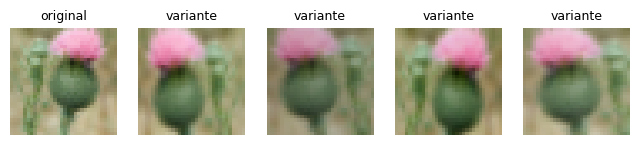

In [13]:
aumentar = v2.Compose([
    v2.RandomResizedCrop(32, scale=(0.6, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
])
COPIAS = 4


def con_variantes(fotos):
    """Las fotos originales más COPIAS variantes de cada una, con su etiqueta y el número de la foto de origen."""
    variantes = torch.stack([aumentar(miniaturas[i]) for i in fotos for _ in range(COPIAS)])
    X = torch.cat([miniaturas[fotos], variantes])
    origen = torch.cat([fotos, fotos.repeat_interleave(COPIAS)])
    return X.reshape(len(X), -1).float() / 255, etiquetas[origen], origen


torch.manual_seed(0)
g = torch.Generator().manual_seed(0)
fotos = torch.randperm(N, generator=g)[:2000]

ejemplo = fotos[0].item()
fig, ejes = plt.subplots(1, 5, figsize=(8, 1.9))
ejes[0].imshow(miniaturas[ejemplo].permute(1, 2, 0))
ejes[0].set_title("original", fontsize=9)
for eje in ejes[1:]:
    eje.imshow(aumentar(miniaturas[ejemplo]).permute(1, 2, 0))
    eje.set_title("variante", fontsize=9)
for eje in ejes:
    eje.axis("off")
plt.show()

Primero la versión equivocada: crear todas las variantes, mezclar las 10.000 imágenes y separar 70% para entrenar y 30% para probar. Después, la correcta: separar las 2.000 fotos originales 70/30 y crear variantes solo de las de entrenamiento. La prueba correcta son fotos originales que el modelo nunca vio en ninguna versión.

In [14]:
inicio = time.perf_counter()

# Mal: aumentar y después dividir
X_todo, y_todo, origen_todo = con_variantes(fotos)
orden = torch.randperm(len(y_todo), generator=g)
corte = int(0.7 * len(y_todo))
e, p = orden[:corte], orden[corte:]
mal = exactitud(vecino_mas_cercano(X_todo[e], y_todo[e], X_todo[p]), y_todo[p])
con_hermana = torch.isin(origen_todo[p], origen_todo[e]).float().mean().item()

# Bien: dividir las fotos y después aumentar solo el entrenamiento
orden = fotos[torch.randperm(len(fotos), generator=g)]
corte = int(0.7 * len(fotos))
fotos_ent, fotos_pru = orden[:corte], orden[corte:]
X_ent_aum, y_ent_aum, _ = con_variantes(fotos_ent)
bien = exactitud(vecino_mas_cercano(X_ent_aum, y_ent_aum, X_flores[fotos_pru]), etiquetas[fotos_pru])
sin_aumento = exactitud(vecino_mas_cercano(X_flores[fotos_ent], etiquetas[fotos_ent], X_flores[fotos_pru]), etiquetas[fotos_pru])

print(f"mal: aumentar y después dividir            : {mal:.1%}")
print(f"     imágenes de prueba con una 'hermana' en entrenamiento: {con_hermana:.1%}")
print(f"bien: dividir y aumentar solo entrenamiento: {bien:.1%}")
print(f"sin aumento                                : {sin_aumento:.1%}")
print(f"({time.perf_counter() - inicio:.0f} s)")

mal: aumentar y después dividir            : 59.4%
     imágenes de prueba con una 'hermana' en entrenamiento: 99.0%
bien: dividir y aumentar solo entrenamiento: 14.7%
sin aumento                                : 15.2%
(31 s)


Con la fuga, el vecino más cercano parece acertar más de la mitad de las veces. Casi todas las imágenes de prueba tienen una hermana (otra versión de la misma foto) en el entrenamiento, y el vecino más cercano la encuentra. La versión correcta da un número cuatro veces menor, que es lo que el modelo hace de verdad con flores nuevas. Y aquí el aumento, bien usado, no ayuda: con y sin variantes la exactitud correcta es casi la misma (incluso un poco menor con ellas). El vecino más cercano no aprende nada de las variantes, solo suma fotos con las que compararse. El aumento está pensado para modelos que se entrenan, como las redes de los módulos siguientes; lo que muestra este experimento es otra cosa: si se aumenta antes de dividir, el número de la prueba deja de significar algo.

## 7. Copias a ambos lados de la división oficial

La fuga anterior la fabricamos nosotros. ¿Puede venir ya en los datos? Si la misma foto está dos veces en el conjunto, una en entrenamiento y otra en prueba, pasa lo mismo que con las variantes. Buscamos copias entre la prueba oficial (6.149 fotos) y entrenamiento más validación oficiales (2.040).

Para comparar miniaturas usamos una **similitud** entre -1 y 1: a cada miniatura le restamos su promedio y la dividimos por su largo, y el producto entre dos de ellas es el coseno del ángulo entre los dos vectores. Vale 1 si los píxeles son iguales, aunque una sea más clara o tenga más contraste que la otra.

fotos de prueba con una foto de referencia de similitud > 0.99: 5
fotos de prueba con una foto de referencia de similitud > 0.98: 6
fotos de prueba con una foto de referencia de similitud > 0.95: 7
fotos de prueba con una foto de referencia de similitud > 0.9: 30


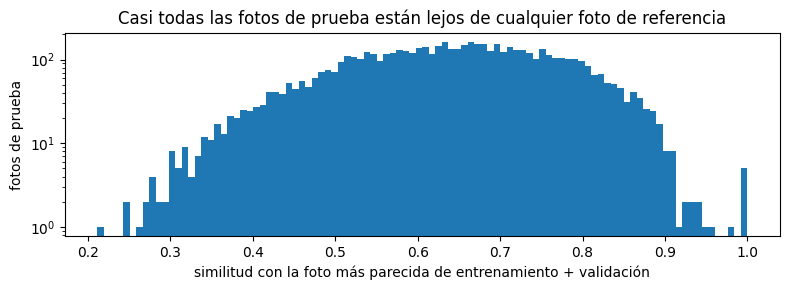

In [15]:
def normalizar_filas(X):
    Z = X - X.mean(dim=1, keepdim=True)
    return Z / Z.norm(dim=1, keepdim=True)


Z_flores = normalizar_filas(X_flores)
de_prueba, de_referencia = oficial["prueba"], referencia
similitud = Z_flores[de_prueba] @ Z_flores[de_referencia].T          # [6149, 2040]
mejor, cual = similitud.max(dim=1)                                    # la foto de referencia más parecida a cada foto de prueba

for umbral in [0.99, 0.98, 0.95, 0.90]:
    print(f"fotos de prueba con una foto de referencia de similitud > {umbral}: {(mejor > umbral).sum().item()}")

fig, eje = plt.subplots(figsize=(8, 3))
eje.hist(mejor.numpy(), bins=100)
eje.set_yscale("log")
eje.set_xlabel("similitud con la foto más parecida de entrenamiento + validación")
eje.set_ylabel("fotos de prueba")
eje.set_title("Casi todas las fotos de prueba están lejos de cualquier foto de referencia")
plt.tight_layout()
plt.show()

La gran mayoría de las fotos de prueba no tiene ninguna foto de referencia parecida, pero hay una cola a la derecha. Una similitud alta no prueba que sea la misma foto: dos fotos distintas de flores amarillas sobre fondo verde pueden parecerse mucho en 32 × 32. Hay que mirarlas. Estas son las 12 parejas más parecidas:

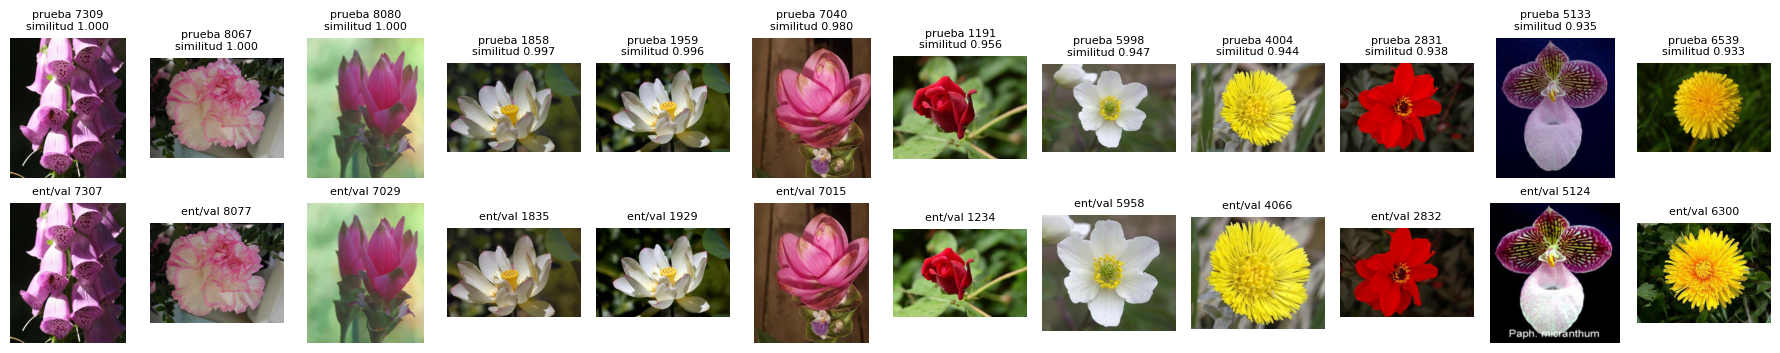

prueba image_07309  ~  referencia image_07307   similitud 1.0000   clases 93 y 93
prueba image_08067  ~  referencia image_08077   similitud 1.0000   clases 30 y 30
prueba image_08080  ~  referencia image_07029   similitud 1.0000   clases 38 y 38
prueba image_01858  ~  referencia image_01835   similitud 0.9973   clases 77 y 77
prueba image_01959  ~  referencia image_01929   similitud 0.9958   clases 77 y 77
prueba image_07040  ~  referencia image_07015   similitud 0.9802   clases 38 y 38
prueba image_01191  ~  referencia image_01234   similitud 0.9564   clases 73 y 73
prueba image_05998  ~  referencia image_05958   similitud 0.9471   clases 68 y 68
prueba image_04004  ~  referencia image_04066   similitud 0.9440   clases 11 y 11
prueba image_02831  ~  referencia image_02832   similitud 0.9376   clases 55 y 55
prueba image_05133  ~  referencia image_05124   similitud 0.9348   clases 1 y 1
prueba image_06539  ~  referencia image_06300   similitud 0.9328   clases 49 y 49


In [16]:
mas_parecidas = torch.argsort(mejor, descending=True)[:12]
parejas = [(de_prueba[j].item(), de_referencia[cual[j]].item(), mejor[j].item()) for j in mas_parecidas]

fig, ejes = plt.subplots(2, 12, figsize=(18, 3.6))
for columna, (i_pru, i_ref, s) in enumerate(parejas):
    for fila, (i, nombre) in enumerate([(i_pru, "prueba"), (i_ref, "ent/val")]):
        with Image.open(f"{CARPETA}/jpg/image_{i + 1:05d}.jpg") as foto:
            foto.draft("RGB", (160, 160))
            ejes[fila, columna].imshow(foto.convert("RGB"))
        ejes[fila, columna].set_title(f"{nombre} {i + 1}" + (f"\nsimilitud {s:.3f}" if fila == 0 else ""), fontsize=8)
        ejes[fila, columna].axis("off")
plt.tight_layout()
plt.show()

for i_pru, i_ref, s in parejas:
    print(f"prueba image_{i_pru + 1:05d}  ~  referencia image_{i_ref + 1:05d}   similitud {s:.4f}   "
          f"clases {etiquetas[i_pru].item()} y {etiquetas[i_ref].item()}")

Revisadas una por una (también a tamaño completo, fuera del notebook):

- Las seis primeras parejas son **la misma foto**. Tres son idénticas o casi idénticas píxel a píxel; las otras tres están guardadas con otro tamaño o comprimidas de otra forma, y una tiene un encuadre un poco distinto.
- La séptima, la octava, la novena y la undécima también son la misma foto con otro recorte o, en la undécima, retocada y con un texto encima.
- La décima son dos fotos distintas de la misma flor, tomadas casi en el mismo momento.
- La duodécima son dos flores distintas de la misma especie.

En total, 10 fotos de la prueba oficial tienen su copia en entrenamiento o validación. La comprobación más estricta es comparar los archivos byte a byte, con un resumen MD5 de cada uno:

In [17]:
archivos_por_resumen = {}
for i in range(N):
    with open(f"{CARPETA}/jpg/image_{i + 1:05d}.jpg", "rb") as archivo:
        resumen = hashlib.md5(archivo.read()).hexdigest()
    archivos_por_resumen.setdefault(resumen, []).append(i)

conjunto = {}
for nombre, indices in oficial.items():
    for i in indices.tolist():
        conjunto[i] = nombre

for indices in archivos_por_resumen.values():
    if len(indices) > 1:
        print("archivos idénticos:", "  y  ".join(f"image_{i + 1:05d} ({conjunto[i]}, clase {etiquetas[i].item()})" for i in indices))

archivos idénticos: image_07307 (entrenamiento, clase 93)  y  image_07309 (prueba, clase 93)
archivos idénticos: image_07323 (prueba, clase 93)  y  image_07328 (prueba, clase 93)
archivos idénticos: image_07885 (prueba, clase 98)  y  image_07886 (prueba, clase 98)
archivos idénticos: image_08067 (prueba, clase 30)  y  image_08077 (validación, clase 30)


Cuatro pares de archivos son idénticos byte a byte, y dos de ellos cruzan la división (prueba con entrenamiento, y prueba con validación). Los otros dos están ambos en la prueba: no filtran nada, pero esas fotos cuentan doble.

¿Cuánto inflan estas copias la exactitud de la prueba oficial? Como son 10 de 6.149 fotos, a lo sumo 0.16 puntos. Lo medimos con el vecino más cercano:

In [18]:
copias_en_prueba = torch.tensor([i_pru for i_pru, _, _ in parejas[:9]] + [parejas[10][0]])
es_copia = torch.isin(de_prueba, copias_en_prueba)
acierto = prediccion == etiquetas[de_prueba]          # la predicción oficial de la sección 1
print(f"fotos de prueba con copia: {es_copia.sum().item()},  aciertos entre ellas: {acierto[es_copia].sum().item()}")
print(f"exactitud con las copias : {acierto.float().mean().item():.2%}")
print(f"exactitud sin las copias : {acierto[~es_copia].float().mean().item():.2%}")

fotos de prueba con copia: 10,  aciertos entre ellas: 10
exactitud con las copias : 15.01%
exactitud sin las copias : 14.87%


Acierta las 10: el vecino más cercano de cada copia es su gemela, incluso en las que tienen otro recorte (a 32 × 32 un recorte un poco distinto sigue siendo casi la misma imagen). En total la exactitud oficial casi no se mueve, porque las copias son pocas. La lección no es que esta fuga sea grave aquí, sino el procedimiento: buscar candidatas con una medida barata, **mirarlas** antes de afirmar nada, y medir el efecto. En otros conjuntos las copias son muchas más; en una búsqueda propia de imágenes juntadas de internet, casi seguro aparecen.

**Un hallazgo de pasada.** La misma búsqueda, dentro de todo el conjunto, encuentra una foto guardada dos veces con etiquetas distintas:

parejas de fotos con similitud > 0.97 en todo el conjunto: 22
con etiquetas distintas: image_07303 (clase 92, prueba)  ~  image_07304 (clase 93, prueba)   similitud 0.9795


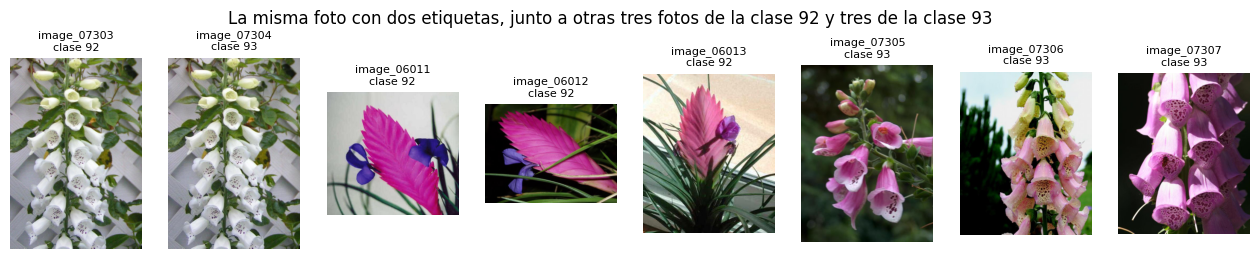

In [19]:
similitud_total = Z_flores @ Z_flores.T                                   # [8189, 8189]
parejas_parecidas = torch.nonzero(torch.triu(similitud_total > 0.97, diagonal=1))     # cada pareja una vez
print("parejas de fotos con similitud > 0.97 en todo el conjunto:", len(parejas_parecidas))
con_etiquetas_distintas = [(a, b) for a, b in parejas_parecidas.tolist() if etiquetas[a] != etiquetas[b]]
for a, b in con_etiquetas_distintas:
    print(f"con etiquetas distintas: image_{a + 1:05d} (clase {etiquetas[a].item()}, {conjunto[a]})  ~  "
          f"image_{b + 1:05d} (clase {etiquetas[b].item()}, {conjunto[b]})   similitud {similitud_total[a, b]:.4f}")
a, b = con_etiquetas_distintas[0]

clase_a, clase_b = etiquetas[a].item(), etiquetas[b].item()
otras_a = [k for k in torch.nonzero(etiquetas == clase_a).flatten().tolist() if k not in (a, b)][:3]
otras_b = [k for k in torch.nonzero(etiquetas == clase_b).flatten().tolist() if k not in (a, b)][:3]
fig, ejes = plt.subplots(1, 8, figsize=(16, 2.6))
for eje, k in zip(ejes, [a, b] + otras_a + otras_b):
    with Image.open(f"{CARPETA}/jpg/image_{k + 1:05d}.jpg") as foto:
        foto.draft("RGB", (160, 160))
        eje.imshow(foto.convert("RGB"))
    eje.set_title(f"image_{k + 1:05d}\nclase {etiquetas[k].item()}", fontsize=8)
    eje.axis("off")
plt.suptitle(f"La misma foto con dos etiquetas, junto a otras tres fotos de la clase {clase_a} y tres de la clase {clase_b}", y=1.05)
plt.show()

Las dos primeras se ven iguales: las mismas flores blancas en forma de campana, en la misma posición (la similitud de sus miniaturas es 0.98), y la salida dice que las dos están en la prueba. Una tiene la clase 92 y la otra la 93. Las tres fotos de la clase 93 de la derecha tienen la misma forma: flores en campana a lo largo de una espiga alta, solo que rosadas. Las tres de la clase 92 son de otra planta: una espiga plana de brácteas rosadas con flores violetas. La etiqueta que no calza es la 92 de image_07303. No es una fuga, es un error de etiqueta, y es el tipo de problema de calidad que trata `05-profundizacion/02_datos_antes_que_el_modelo`.

## 8. Elegir con la prueba

La fuga más difícil de ver no está en el código de los datos sino en el proceso: probar varias versiones del modelo y quedarse con la que mejor sale en la prueba. La guía de scikit-learn lo explica al presentar la validación cruzada: al ajustar hiperparámetros sigue habiendo riesgo de sobreajustar a la prueba, porque se pueden mover hasta que el modelo rinda lo mejor posible en ella; así el conocimiento de la prueba se "filtra" al modelo y las métricas dejan de informar sobre la generalización ([sección 3.1](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-evaluating-estimator-performance)).

Para verlo sin ninguna ambigüedad usamos modelos que no saben nada: 1.000 clasificadores lineales con pesos al azar sobre datos cuya etiqueta es al azar. Es como entrenar mil veces con mil semillas un modelo que no aprende. Cada uno es una función fija, y en datos nuevos todos aciertan 50%. Con 100 ejemplos de prueba, elegimos el mejor de los primeros m:

el mejor de    1 modelos: 49.9% en la prueba,  50.0% en 10.000 datos nuevos
el mejor de    3 modelos: 53.8% en la prueba,  50.1% en 10.000 datos nuevos
el mejor de   10 modelos: 57.2% en la prueba,  50.0% en 10.000 datos nuevos
el mejor de   30 modelos: 60.0% en la prueba,  49.9% en 10.000 datos nuevos
el mejor de  100 modelos: 62.1% en la prueba,  50.0% en 10.000 datos nuevos
el mejor de  300 modelos: 63.9% en la prueba,  49.9% en 10.000 datos nuevos
el mejor de 1000 modelos: 65.6% en la prueba,  50.0% en 10.000 datos nuevos


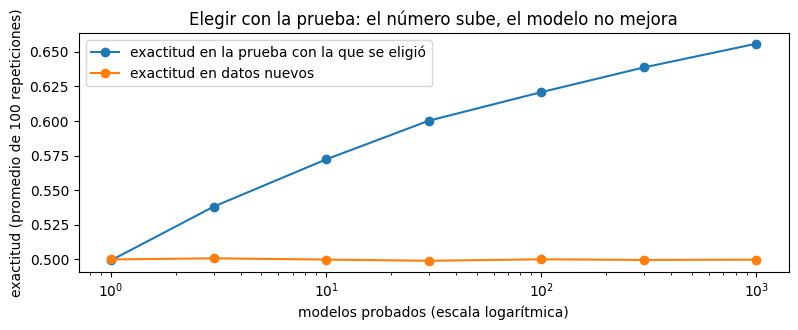

In [20]:
def elegir_el_mejor(semilla, n_modelos=1000, n_evaluacion=100, dimension=20):
    g = torch.Generator().manual_seed(semilla)
    pesos = torch.randn(n_modelos, dimension, generator=g)                  # 1.000 modelos que adivinan

    def aciertos(n):
        X = torch.randn(n, dimension, generator=g)
        y = torch.randint(0, 2, (n,), generator=g)                           # etiquetas sin relación con X
        return ((X @ pesos.T > 0).long() == y[:, None]).float().mean(dim=0)  # exactitud de cada modelo

    return aciertos(n_evaluacion), aciertos(n_evaluacion), aciertos(10_000)  # prueba, validación, datos nuevos


cantidades = [1, 3, 10, 30, 100, 300, 1000]
mejor_en_prueba, en_datos_nuevos = [], []
for semilla in range(100):
    prueba_m, _, nuevos_m = elegir_el_mejor(semilla)
    fila_prueba, fila_nuevos = [], []
    for m in cantidades:
        elegido = prueba_m[:m].argmax()
        fila_prueba.append(prueba_m[elegido].item())
        fila_nuevos.append(nuevos_m[elegido].item())
    mejor_en_prueba.append(fila_prueba)
    en_datos_nuevos.append(fila_nuevos)
mejor_en_prueba, en_datos_nuevos = np.array(mejor_en_prueba).mean(0), np.array(en_datos_nuevos).mean(0)

for m, a, b in zip(cantidades, mejor_en_prueba, en_datos_nuevos):
    print(f"el mejor de {m:4d} modelos: {a:.1%} en la prueba,  {b:.1%} en 10.000 datos nuevos")

fig, eje = plt.subplots(figsize=(8, 3.4))
eje.plot(cantidades, mejor_en_prueba, marker="o", label="exactitud en la prueba con la que se eligió")
eje.plot(cantidades, en_datos_nuevos, marker="o", label="exactitud en datos nuevos")
eje.set_xscale("log")
eje.set_xlabel("modelos probados (escala logarítmica)")
eje.set_ylabel("exactitud (promedio de 100 repeticiones)")
eje.set_title("Elegir con la prueba: el número sube, el modelo no mejora")
eje.legend()
plt.tight_layout()
plt.show()

Con un solo modelo, la prueba dice la verdad: 50%. Con 10, el elegido ya parece acertar 57%; con 1.000, 66%. En datos nuevos todos siguen en 50%. Ninguno es mejor que otro; la prueba solo eligió al que tuvo más suerte con esos 100 ejemplos. Y no hace falta hacer trampa a propósito: basta con mirar la prueba varias veces mientras se ajusta algo.

El remedio que propone la guía es apartar otro conjunto, la **validación**: se elige con ella y la prueba se mira una sola vez, al final ([sección 3.1](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-evaluating-estimator-performance)). Con los mismos 1.000 modelos:

In [21]:
prueba_final, mejor_en_validacion = [], []
for semilla in range(100):
    prueba_m, validacion_m, _ = elegir_el_mejor(semilla)
    elegido = validacion_m.argmax()
    mejor_en_validacion.append(validacion_m[elegido].item())
    prueba_final.append(prueba_m[elegido].item())
print(f"el mejor de 1.000 según la validación: {np.mean(mejor_en_validacion):.1%} en la validación")
print(f"ese mismo modelo, en la prueba       : {np.mean(prueba_final):.1%}")

el mejor de 1.000 según la validación: 65.6% en la validación
ese mismo modelo, en la prueba       : 50.5%


La validación queda igual de optimista (es la que se usó para elegir), pero la prueba, que no participó, vuelve a decir la verdad. Por eso la prueba se usa una sola vez: en el momento en que se usa para decidir algo, se convierte en otra validación y hace falta una prueba nueva. Es la regla que seguimos desde el módulo 1 (`05-profundizacion/06_proyecto_de_punta_a_punta`, sección 10). Brownlee la recomienda como su segunda técnica contra la fuga: guardar un conjunto aparte como comprobación final ([*Hold Back a Validation Dataset*](https://machinelearningmastery.com/data-leakage-machine-learning/)).

## 9. Validación cruzada a mano

Apartar una validación tiene un costo: con tres conjuntos quedan menos datos para entrenar, y el resultado depende de qué ejemplos cayeron en cada uno. La **validación cruzada** lo resuelve. En la versión de $k$ pliegues, el conjunto de desarrollo (todo menos la prueba) se divide en $k$ partes; se entrena con $k - 1$ y se evalúa con la que queda, rotando, y se informa el promedio. La prueba sigue aparte para la evaluación final ([sección 3.1](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-evaluating-estimator-performance)).

Los pliegues son solo listas de índices. Escribimos dos formas de armarlos: la simple (`KFold` en scikit-learn), que corta el orden tal como viene o mezclado, y la **estratificada** (`StratifiedKFold`), que reparte cada clase por separado para que todos los pliegues tengan aproximadamente la misma proporción de cada clase ([sección 3.1.2.2.1](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold)):

In [22]:
def pliegues_simples(n, k, mezclar=False, g=None):
    orden = torch.randperm(n, generator=g) if mezclar else torch.arange(n)
    return list(torch.tensor_split(orden, k))


def pliegues_estratificados(y, k, g):
    pliegues = [[] for _ in range(k)]
    for clase in torch.unique(y):
        de_la_clase = torch.nonzero(y == clase).flatten()
        de_la_clase = de_la_clase[torch.randperm(len(de_la_clase), generator=g)]
        for numero, parte in enumerate(torch.tensor_split(de_la_clase, k)):
            pliegues[(numero + clase.item()) % k].append(parte)       # rotar para que los restos no caigan siempre en el primero
    return [torch.cat(p) for p in pliegues]


def validacion_cruzada(X, y, pliegues, predecir):
    exactitudes, clases_sin_entrenar = [], []
    for pliegue in pliegues:
        fuera = torch.ones(len(y), dtype=torch.bool)
        fuera[pliegue] = False                                        # entrenar con todo lo que no es el pliegue
        exactitudes.append(exactitud(predecir(X[fuera], y[fuera], X[pliegue]), y[pliegue]))
        clases_sin_entrenar.append(len(set(y[pliegue].tolist()) - set(y[fuera].tolist())))
    return np.array(exactitudes), clases_sin_entrenar

Las aplicamos a las 8.189 flores con el vecino más cercano y 5 pliegues. Recordemos un detalle de los archivos: vienen agrupados por clase (`00-acceso/01_un_dataset_propio`).

In [23]:
g = torch.Generator().manual_seed(0)
for nombre, pliegues in [("simple, en el orden de los archivos", pliegues_simples(N, 5)),
                         ("simple, mezclado", pliegues_simples(N, 5, mezclar=True, g=g)),
                         ("estratificado", pliegues_estratificados(etiquetas, 5, g))]:
    resultado, sin_entrenar = validacion_cruzada(X_flores, etiquetas, pliegues, vecino_mas_cercano)
    clases_por_pliegue = [len(torch.unique(etiquetas[p])) for p in pliegues]
    print(f"{nombre}:")
    print(f"   exactitud por pliegue {np.round(resultado * 100, 1)}%   promedio {resultado.mean():.1%}")
    print(f"   clases en cada pliegue {clases_por_pliegue},  clases del pliegue que no están en su entrenamiento {sin_entrenar}")

simple, en el orden de los archivos:
   exactitud por pliegue [0.1 0.3 0.8 0.5 1.3]%   promedio 0.6%
   clases en cada pliegue [10, 16, 22, 30, 37],  clases del pliegue que no están en su entrenamiento [6, 14, 14, 27, 28]


simple, mezclado:
   exactitud por pliegue [20.3 18.6 20.6 20.3 21.1]%   promedio 20.2%
   clases en cada pliegue [102, 102, 102, 102, 102],  clases del pliegue que no están en su entrenamiento [0, 0, 0, 0, 0]


estratificado:
   exactitud por pliegue [21.1 19.6 20.2 19.6 19.7]%   promedio 20.1%
   clases en cada pliegue [102, 102, 102, 102, 102],  clases del pliegue que no están en su entrenamiento [0, 0, 0, 0, 0]


Sin mezclar, la validación cruzada da menos de 1%, por debajo del azar. Cada pliegue es un tramo seguido de archivos, así que contiene pocas clases (entre 10 y 37), y muchas de ellas no aparecen en el resto de los datos con los que se entrena. El modelo no puede acertar clases que nunca vio. scikit-learn lo advierte: si el orden de los datos no es arbitrario, por ejemplo con las muestras de una misma clase seguidas, mezclar antes puede ser esencial ([sección 3.1.3](https://scikit-learn.org/stable/modules/cross_validation.html#a-note-on-shuffling)). Además, `KFold` no mezcla por defecto.

Mezclado o estratificado, todos los pliegues tienen las 102 clases y la estimación ronda el 20%. Aquí las dos coinciden porque hay muchas fotos por clase; la estratificación importa cuando hay clases raras, que una división al azar puede dejar fuera de un pliegue ([sección 3.1.2.2](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-with-stratification-based-on-class-labels)).

**Preparar dentro de cada pliegue.** La validación cruzada no protege de las fugas de las secciones anteriores si la preparación se hace afuera. Brownlee lo pone como su primera técnica: recalcular toda la preparación dentro de cada pliegue, incluida la selección de características ([*Perform Data Preparation Within Cross Validation Folds*](https://machinelearningmastery.com/data-leakage-machine-learning/)). Lo comprobamos con los datos al azar de la sección 3: elegir las 25 características con los 200 ejemplos y después validar, contra elegirlas dentro de cada pliegue:

In [24]:
def centroide_con_seleccion(k=25):
    """El clasificador de la sección 3, pero eligiendo las k características con los datos que recibe para entrenar."""
    def predecir(X_ent, y_ent, X_pru):
        elegidas = puntaje_anova(X_ent, y_ent).topk(k).indices
        return centroide_mas_cercano(X_ent[:, elegidas], y_ent, X_pru[:, elegidas])
    return predecir


afuera, adentro = [], []
for semilla in range(20):
    g = torch.Generator().manual_seed(semilla)
    X = torch.randn(200, 10_000, generator=g)
    y = torch.randint(0, 2, (200,), generator=g)
    pliegues = pliegues_estratificados(y, 5, g)
    elegidas = puntaje_anova(X, y).topk(25).indices                         # mal: elegir con los 200
    afuera.append(validacion_cruzada(X[:, elegidas], y, pliegues, centroide_mas_cercano)[0].mean())
    adentro.append(validacion_cruzada(X, y, pliegues, centroide_con_seleccion())[0].mean())   # bien
print(f"elegir afuera y después validar  : {np.mean(afuera):.1%} ± {np.std(afuera):.1%}")
print(f"elegir dentro de cada pliegue    : {np.mean(adentro):.1%} ± {np.std(adentro):.1%}")

elegir afuera y después validar  : 85.9% ± 2.0%
elegir dentro de cada pliegue    : 50.9% ± 3.7%


Afuera, la validación cruzada repite la ilusión de la sección 3. Adentro, vuelve al azar. En scikit-learn esto es lo que garantiza un `Pipeline`: dentro de la validación cruzada, cada paso se ajusta solo con los datos de entrenamiento de cada pliegue ([sección 12.2.1](https://scikit-learn.org/stable/common_pitfalls.html#how-to-avoid-data-leakage)).

**El flujo completo.** Juntamos todo: apartamos la prueba (15%), elegimos un hiperparámetro con validación cruzada estratificada sobre el resto, y miramos la prueba una vez. El hiperparámetro es cuántos vecinos votan, $k$:

In [25]:
def k_vecinos(k):
    def predecir(X_ent, y_ent, X_pru):
        vecinos = torch.cdist(X_pru, X_ent).topk(k, largest=False).indices
        votos = torch.zeros(len(X_pru), 102)
        votos.scatter_add_(1, y_ent[vecinos], torch.ones(vecinos.shape))
        return votos.argmax(dim=1)            # en un empate gana la clase de número menor
    return predecir


desarrollo = torch.cat([ent, val])                      # la división 70/15/15 de la sección 4
X_des, y_des = X_flores[desarrollo], etiquetas[desarrollo]
pliegues = pliegues_estratificados(y_des, 5, torch.Generator().manual_seed(0))

inicio = time.perf_counter()
puntajes = {}
for k in [1, 3, 5, 9, 15, 25]:
    puntajes[k] = validacion_cruzada(X_des, y_des, pliegues, k_vecinos(k))[0].mean()
    print(f"k = {k:2d}: validación cruzada {puntajes[k]:.2%}")
k_elegido = max(puntajes, key=puntajes.get)
final = exactitud(k_vecinos(k_elegido)(X_des, y_des, X_flores[pru]), etiquetas[pru])
print(f"\nelegido k = {k_elegido}; la prueba, una sola vez: {final:.2%}   ({time.perf_counter() - inicio:.0f} s)")

k =  1: validación cruzada 19.54%


k =  3: validación cruzada 17.15%


k =  5: validación cruzada 17.96%


k =  9: validación cruzada 18.26%


k = 15: validación cruzada 17.92%


k = 25: validación cruzada 17.31%



elegido k = 1; la prueba, una sola vez: 20.34%   (40 s)


La validación cruzada elige un solo vecino, y la prueba, mirada una vez, da un número parecido al de la validación cruzada. Ese es el número que se informa.

## 10. Grupos que dependen entre sí

Todo lo anterior supone que los ejemplos son independientes entre sí. La guía de scikit-learn advierte que ese supuesto rara vez se cumple en la práctica, y que si los datos tienen una estructura de grupos (muestras de distintos sujetos, experimentos o instrumentos) es más seguro validar por grupos ([sección 3.1.2.1](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-i-i-d-data)). Su ejemplo son datos médicos con varias muestras por paciente: lo que interesa es si el modelo generaliza a pacientes nuevos, y para medirlo hay que asegurar que todas las muestras de un pliegue de validación vengan de grupos que no están en su entrenamiento ([sección 3.1.2.4](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data)). `GroupKFold` hace eso, y permite detectar el sobreajuste a rasgos propios de cada sujeto ([sección 3.1.2.4.1](https://scikit-learn.org/stable/modules/cross_validation.html#group-k-fold)).

En el jardín, el grupo natural es la planta: varias fotos de la misma planta comparten la luz, el fondo y la forma de esa planta en particular. Oxford Flowers 102 no dice de qué planta viene cada foto, así que construimos un caso con mediciones inventadas: 5 especies, 8 plantas de cada una y 10 fotos de cada planta, con 20 números por foto. La especie mueve un poco los números; cada planta tiene además su propio sello, más fuerte, y cada foto agrega un poco de ruido.

In [26]:
g = torch.Generator().manual_seed(0)
ESPECIES, PLANTAS, FOTOS, DIMENSION = 5, 8, 10, 20
centro_especie = torch.randn(ESPECIES, DIMENSION, generator=g)


def fotografiar(centro, plantas_por_especie, g):
    X, y, planta = [], [], []
    for especie in range(ESPECIES):
        for _ in range(plantas_por_especie):
            sello = centro[especie] + 2.0 * torch.randn(DIMENSION, generator=g)    # lo propio de esta planta
            X.append(sello + 0.5 * torch.randn(FOTOS, DIMENSION, generator=g))             # 10 fotos de la planta
            y += [especie] * FOTOS
            planta += [len(planta) // FOTOS] * FOTOS
    return torch.cat(X), torch.tensor(y), torch.tensor(planta)


X_jardin, y_jardin, planta_jardin = fotografiar(centro_especie, PLANTAS, g)
X_nuevas, y_nuevas, _ = fotografiar(centro_especie, 20, g)                     # plantas que el modelo nunca vio


def pliegues_por_grupo(grupos, k, g):
    distintos = torch.unique(grupos)
    distintos = distintos[torch.randperm(len(distintos), generator=g)]
    return [torch.nonzero(torch.isin(grupos, parte)).flatten() for parte in torch.tensor_split(distintos, k)]


al_azar, _ = validacion_cruzada(X_jardin, y_jardin, pliegues_simples(len(y_jardin), 5, mezclar=True, g=g), vecino_mas_cercano)
por_planta, _ = validacion_cruzada(X_jardin, y_jardin, pliegues_por_grupo(planta_jardin, 5, g), vecino_mas_cercano)
en_uso = exactitud(vecino_mas_cercano(X_jardin, y_jardin, X_nuevas), y_nuevas)

print(f"{len(y_jardin)} fotos de {len(torch.unique(planta_jardin))} plantas; el azar es {1 / ESPECIES:.0%}")
print(f"validación cruzada mezclando fotos: {al_azar.mean():.1%}")
print(f"validación cruzada por planta     : {por_planta.mean():.1%}")
print(f"plantas nuevas                    : {en_uso:.1%}")

400 fotos de 40 plantas; el azar es 20%
validación cruzada mezclando fotos: 100.0%
validación cruzada por planta     : 51.2%
plantas nuevas                    : 64.4%


Mezclando las fotos, la validación cruzada promete 100%: para cada foto de validación, el vecino más cercano es otra foto de la misma planta, y el modelo reconoce la planta, no la especie. Por planta, la estimación baja a 51%, mucho más cerca de lo que pasa con plantas nuevas (64%), pero no igual. La función de reparto de pliegues es la misma de antes; lo único que cambia es qué se reparte: plantas enteras en vez de fotos sueltas.

¿Por qué no coincide del todo? Hay dos sospechosos. Uno: cada pliegue entrena con 32 plantas, y el modelo final con 40. Otro: 40 plantas son pocas, así que la estimación depende de qué plantas tocaron. Para separarlos repetimos todo en cinco jardines más, inventados igual con otras semillas. En cada uno medimos las dos validaciones cruzadas y la exactitud en plantas nuevas de dos modelos: uno entrenado con las 40 plantas y otro con solo 32 (el promedio de 10 sorteos de cuáles 32).

In [27]:
def otro_jardin(semilla, sorteos=10):
    g = torch.Generator().manual_seed(semilla)
    centro = torch.randn(ESPECIES, DIMENSION, generator=g)
    X, y, planta = fotografiar(centro, PLANTAS, g)
    X_n, y_n, _ = fotografiar(centro, 20, g)
    mezclando, _ = validacion_cruzada(X, y, pliegues_simples(len(y), 5, mezclar=True, g=g), vecino_mas_cercano)
    por_planta, _ = validacion_cruzada(X, y, pliegues_por_grupo(planta, 5, g), vecino_mas_cercano)
    con_40 = exactitud(vecino_mas_cercano(X, y, X_n), y_n)
    con_32 = []
    for _ in range(sorteos):
        elegidas = torch.isin(planta, torch.randperm(ESPECIES * PLANTAS, generator=g)[:32])
        con_32.append(exactitud(vecino_mas_cercano(X[elegidas], y[elegidas], X_n), y_n))
    return mezclando.mean(), por_planta.mean(), np.mean(con_32), con_40


filas = np.array([otro_jardin(semilla) for semilla in range(1, 6)])
print("jardín   mezclando fotos   por planta   plantas nuevas (con 32)   plantas nuevas (con 40)")
for semilla, (a, b, c, d) in zip(range(1, 6), filas):
    print(f"{semilla:>6}   {a:>15.1%}   {b:>10.1%}   {c:>23.1%}   {d:>23.1%}")
a, b, c, d = filas.mean(axis=0)
print(f"{'media':>6}   {a:>15.1%}   {b:>10.1%}   {c:>23.1%}   {d:>23.1%}")

jardín   mezclando fotos   por planta   plantas nuevas (con 32)   plantas nuevas (con 40)
     1            100.0%        67.3%                     56.9%                     57.2%
     2            100.0%        54.5%                     56.9%                     59.1%
     3            100.0%        40.0%                     45.7%                     49.0%
     4            100.0%        38.5%                     49.5%                     50.5%
     5            100.0%        63.0%                     52.4%                     51.4%
 media            100.0%        52.6%                     52.3%                     53.4%


Mezclando fotos, los cinco jardines prometen 100%. Por planta, la estimación va de 38% a 67% según el jardín: a veces queda más de 10 puntos por encima de lo que pasa con plantas nuevas, y a veces más de 10 por debajo. En promedio, las dos quedan cerca (52.6% y 53.4%). Entrenar con 32 plantas en vez de 40 cuesta alrededor de un punto (52.3% contra 53.4% en promedio), así que explica poco. Lo que pesa es el azar: con solo 40 plantas, una validación cruzada por planta es una estimación ruidosa. Sigue siendo la que hay que usar, porque no promete de más como la mezclada; solo hay que leerla con su margen de error, y con pocos grupos ese margen es grande.

Las copias de la sección 7 son el caso extremo de un grupo: la misma foto, dos veces. Y la división por tiempo de la sección 5 es la misma idea con el tiempo en el papel del grupo.

## 11. Una lista de verificación

Lo que conviene revisar en cualquier proyecto, con la sección donde lo medimos:

1. **Dividir primero**, antes de cualquier preparación ([scikit-learn, sección 12.2.1](https://scikit-learn.org/stable/common_pitfalls.html#how-to-avoid-data-leakage)). Las secciones 3, 4 y 6.
2. **Todo lo que se ajusta a los datos se ajusta solo con el entrenamiento**: medias y desviaciones, características elegidas, valores para rellenar faltantes. La validación y la prueba solo se transforman con lo ya calculado. Secciones 3 a 5, y el `Dataset` del proyecto de punta a punta del módulo 1 (sección 7).
3. **El aumento de datos va después de dividir y solo en el entrenamiento** (`03-robustez/01_pipelines_a_prueba_de_fallas`). Sección 6.
4. **Buscar copias y casi copias entre divisiones**, y mirarlas antes de concluir. Sección 7.
5. **Si los datos tienen grupos** (la misma planta, el mismo paciente, la misma sesión), **dividir por grupo**. Sección 10.
6. **Si los datos cambian con el tiempo, dividir por tiempo**: el pasado para entrenar y el futuro para probar. Sección 5.
7. **Mezclar antes de dividir si el orden no es arbitrario**, como los archivos de las flores agrupados por clase (`02-carga/01_division_y_dataloader`). Salvo el caso anterior. Sección 9.
8. **Elegir con la validación o la validación cruzada, y mirar la prueba una sola vez.** Sección 8, y el proyecto de punta a punta del módulo 1 (secciones 5 y 10).
9. **Desconfiar de un resultado demasiado bueno** ([Brownlee, *Do I have Data Leakage?*](https://machinelearningmastery.com/data-leakage-machine-learning/)).

## 12. Resumen

- La **fuga de datos** es usar, al construir el modelo, información que no va a estar disponible al predecir. No produce errores: produce estimaciones demasiado optimistas.
- **Elegir características con todos los datos** convierte etiquetas al azar en 86% de exactitud aparente; elegirlas solo con el entrenamiento devuelve el 50% honesto. La causa es elegir las características que por casualidad separan también la prueba.
- **Normalizar con todos los datos** es una fuga en principio, pero con las flores el efecto es nulo: las estadísticas de entrenamiento y de todo el conjunto difieren en menos de 0.0005. Normalizar la prueba **con sus propias estadísticas** sí puede ser enorme cuando los datos cambian: 95.7% contra un 73.5% honesto.
- Con **datos que cambian con el tiempo**, dividir al azar promete 88.5% y dividir por tiempo 73.5%; en uso, el modelo tiene 62%.
- **Aumentar antes de dividir** pone variantes de la misma foto a ambos lados: el vecino más cercano pasa de 15% a 59%.
- La división oficial de Oxford Flowers 102 tiene **10 fotos de prueba con su copia** en entrenamiento o validación (cuatro pares de archivos son idénticos byte a byte). El efecto en la exactitud es mínimo porque son pocas. De pasada apareció una foto guardada dos veces con etiquetas distintas.
- **Elegir con la prueba** entre 1.000 modelos que adivinan hace que el elegido parezca acertar 66%; en datos nuevos tiene 50%. Se elige con validación y la prueba se mira una vez.
- La **validación cruzada** reemplaza a una validación fija. Sin mezclar, con los archivos agrupados por clase, da menos de 1%. La preparación va **dentro** de cada pliegue.
- Si los datos tienen **grupos**, se valida por grupo: mezclando fotos de las mismas plantas la estimación es 100%; por planta, 51%; con plantas nuevas, 64%. Con pocos grupos esa estimación es ruidosa: en otros cinco jardines fue de 38% a 67%.

## Ejercicios

1. Antes de ejecutar: en la sección 3, ¿qué crees que pasa con la exactitud con fuga si se eligen 5 características en vez de 25? ¿Y 500? Compruébalo y explica la tendencia.
2. En la sección 3, cambia el número de características al azar de 10.000 a 100. ¿La fuga sigue siendo tan grande? ¿Por qué depende de cuántas características hay para elegir?
3. En la sección 5, haz que el sensor se descalibre el doble de rápido. ¿Cómo cambian la estimación al azar, la estimación por tiempo y el resultado en uso? Escribe una versión de validación cruzada que respete el tiempo, como `TimeSeriesSplit`: cada pliegue entrena con los meses anteriores y valida con el siguiente.
4. En la sección 6, cambia el número de variantes por foto (1, 2, 8). ¿Cómo crece la exactitud con fuga? ¿Por qué con una sola variante ya hay fuga?
5. En la sección 7, busca copias **dentro** de la prueba oficial con umbrales de 0.99 y 0.97 y revisa algunas parejas. ¿Cuántas fotos de prueba cuentan más de una vez?
6. Repite la sección 8 con 1.000 ejemplos de prueba en vez de 100. ¿Cuánto sube ahora el mejor de 1.000? Relaciónalo con el ruido de una exactitud medida con pocos ejemplos.
7. Construye una fuga de grupos con las flores: trata cada foto original de la sección 6 y sus 4 variantes como un grupo, y compara la validación cruzada mezclando imágenes contra la validación cruzada por grupo.

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **scikit-learn**, [*12. Common pitfalls and recommended practices*](https://scikit-learn.org/stable/common_pitfalls.html) (documentación de la versión 1.9.1):
  - [Sección 12.2, *Data leakage*](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage): "Data leakage occurs when information that would not be available at prediction time is used when building the model. This results in overly optimistic performance estimates, for example from cross-validation, and thus poorer performance when the model is used on actually novel data, for example during production." "A common cause is not keeping the test and train data subsets separate. Test data should never be used to make choices about the model. The general rule is to never call fit on the test data." "if you have a normalization step where you divide by the average value, the average should be the average of the train subset, not the average of all the data. If the test subset is included in the average calculation, information from the test subset is influencing the model."
  - [Sección 12.2.1, *How to avoid data leakage*](https://scikit-learn.org/stable/common_pitfalls.html#how-to-avoid-data-leakage): "Always split the data into train and test subsets first, particularly before any preprocessing steps." "The scikit-learn pipeline is a great way to prevent data leakage as it ensures that the appropriate method is performed on the correct data subset."
  - [Sección 12.2.2, *Data leakage during pre-processing*](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage-during-pre-processing): "This risk of leakage is however relevant with almost all transformations in scikit-learn, including (but not limited to) StandardScaler, SimpleImputer, and PCA." "we will create this binary classification problem with 10,000 randomly generated features" (con `n_samples = 200` y `SelectKBest(k=25)`); "Using all the data to perform feature selection results in an accuracy score much higher than chance, even though our targets are completely random", con resultado 0.76; y, separando primero, "The score is now what we would expect for the data, close to chance", con resultado 0.5.
- **scikit-learn**, [*3.1. Cross-validation: evaluating estimator performance*](https://scikit-learn.org/stable/modules/cross_validation.html):
  - [Sección 3.1](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-evaluating-estimator-performance): "there is still a risk of overfitting on the test set because the parameters can be tweaked until the estimator performs optimally. This way, knowledge about the test set can “leak” into the model and evaluation metrics no longer report on generalization performance." "yet another part of the dataset can be held out as a so-called “validation set”: training proceeds on the training set, after which evaluation is done on the validation set, and when the experiment seems to be successful, final evaluation can be done on the test set." "A test set should still be held out for final evaluation, but the validation set is no longer needed when doing CV." "A model is trained using k-1 of the folds as training data; the resulting model is validated on the remaining part of the data".
  - [Sección 3.1.2.1](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-i-i-d-data): "While i.i.d. data is a common assumption in machine learning theory, it rarely holds in practice." "if we know that the generative process has a group structure (samples collected from different subjects, experiments, measurement devices), it is safer to use group-wise cross-validation."
  - [Sección 3.1.2.2](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-with-stratification-based-on-class-labels): "cross-validation splitting can generate train or validation folds without any occurrence of a particular class." [Sección 3.1.2.2.1](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold): "StratifiedKFold is a variation of K-fold which returns stratified folds: each set contains approximately the same percentage of samples of each target class as the complete set."
  - [Sección 3.1.2.4](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data): "An example would be when there is medical data collected from multiple patients, with multiple samples taken from each patient." "we need to ensure that all the samples in the validation fold come from groups that are not represented at all in the paired training fold." [Sección 3.1.2.4.1](https://scikit-learn.org/stable/modules/cross_validation.html#group-k-fold): "GroupKFold is a variation of K-fold which ensures that the same group is not represented in both testing and training sets." "GroupKFold makes it possible to detect this kind of overfitting situations."
  - [Sección 3.1.2.6](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data): la validación cruzada para series de tiempo, `TimeSeriesSplit`.
  - [Sección 3.1.3, *A note on shuffling*](https://scikit-learn.org/stable/modules/cross_validation.html#a-note-on-shuffling): "If the data ordering is not arbitrary (e.g. samples with the same class label are contiguous), shuffling it first may be essential to get a meaningful cross-validation result. However, the opposite may be true if the samples are not independently and identically distributed. For example, if samples correspond to news articles, and are ordered by their time of publication, then shuffling the data will likely lead to a model that is overfit and an inflated validation score". "By default no shuffling occurs, including for the (stratified) K fold cross-validation".
- **Jason Brownlee**, [*Data Leakage in Machine Learning*](https://machinelearningmastery.com/data-leakage-machine-learning/), Machine Learning Mastery (2016, actualizado el 15 de agosto de 2020):
  - *What is Data Leakage in Machine Learning?*: "Data leakage can cause you to create overly optimistic if not completely invalid predictive models." "Data leakage is when information from outside the training dataset is used to create the model."
  - *Do I have Data Leakage?*: "An easy way to know you have data leakage is if you are achieving performance that seems a little too good to be true." Y, entre los conjuntos donde es más problemática: "Analog observations like sound and images where samples are stored in separate files that have a size and a time stamp."
  - *1. Perform Data Preparation Within Cross Validation Folds*: "if you normalize or standardize your entire dataset, then estimate the performance of your model using cross validation, you have committed the sin of data leakage." "it is a good idea to re-prepare or re-calculate any required data preparation within your cross validation folds including tasks like feature selection, outlier removal, encoding, feature scaling and projection methods for dimensionality reduction, and more."
  - *2. Hold Back a Validation Dataset*: "Once you have completed your modeling process and actually created your final model, evaluate it on the validation dataset."
  - *5 Tips to Combat Data Leakage*: "Temporal Cutoff. Remove all data just prior to the event of interest, focusing on the time you learned about a fact or observation rather than the time the observation occurred."

**Documentación de otras librerías**

- [`SelectKBest`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html), scikit-learn: "Select features according to the k highest scores." "Default is f_classif". [`f_classif`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html): "Compute the ANOVA F-value for the provided sample."
- [`Image.draft`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.draft), Pillow: "Configures the image file loader so it returns a version of the image that as closely as possible matches the given mode and size." "It is currently implemented only for JPEG and MPO images."

**Lo que no viene de una fuente** son los números de este notebook (exactitudes, estadísticas, similitudes y conteos): todos salen de las celdas de código. También son nuestros el caso del sensor que se descalibra, el de las plantas con varias fotos, el experimento de aumentar antes de dividir y la búsqueda de copias en Oxford Flowers 102, con su revisión visual de las parejas y la foto con dos etiquetas.